In [29]:
import pandas as pd
df = pd.read_csv('/content/ecommerce_sales_analysis_dataset.csv')
df.head()


,Order_ID,Order_Date,Customer_ID,City,Region,Product,Category,Quantity,Unit_Price,Discount,Revenue,Profit
0,ORD0001,2025-12-15,C1075,Delhi,North,Backpack,Fashion,3,1834.87,0.1,4954.14,1050.46
1,ORD0002,2025-03-29,C1088,Bengaluru,South,Air Fryer,Home & Kitchen,4,6696.16,0.0,26784.62,9875.96
2,ORD0003,2025-10-21,C1089,Mumbai,West,Water Bottle,Home & Kitchen,4,672.59,0.0,2690.38,739.98
3,ORD0004,2025-02-28,C1051,Delhi,North,Laptop,Electronics,2,60211.31,0.0,120422.62,40154.41
4,ORD0005,2025-02-24,C1018,Nagpur,Central,Water Bottle,Home & Kitchen,1,715.06,0.0,715.06,247.33


In [30]:
print(df.shape)

(600, 12)


In [31]:
print(df.columns)

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'City', 'Region', 'Product',
       'Category', 'Quantity', 'Unit_Price', 'Discount', 'Revenue', 'Profit'],
      dtype='object')


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Order_ID     600 non-null    object 
 1   Order_Date   600 non-null    object 
 2   Customer_ID  600 non-null    object 
 3   City         597 non-null    object 
 4   Region       600 non-null    object 
 5   Product      600 non-null    object 
 6   Category     600 non-null    object 
 7   Quantity     600 non-null    int64  
 8   Unit_Price   600 non-null    float64
 9   Discount     597 non-null    float64
 10  Revenue      600 non-null    float64
 11  Profit       600 non-null    float64
dtypes: float64(4), int64(1), object(7)
memory usage: 56.4+ KB


In [33]:
print(df.describe())

         Quantity    Unit_Price    Discount        Revenue        Profit
count  600.000000    600.000000  597.000000     600.000000    600.000000
mean     3.011667  11435.169150    0.067504   31990.971467   7196.441000
std      1.402906  15832.791862    0.060819   49837.600994  12253.145063
min      1.000000    632.120000    0.000000     526.730000   -454.100000
25%      2.000000   1967.685000    0.000000    4748.312500    900.570000
50%      3.000000   5946.345000    0.050000   13098.500000   2615.390000
75%      4.000000   9702.392500    0.100000   31165.745000   7217.330000
max      5.000000  60211.310000    0.200000  299903.860000  86189.820000


In [34]:
print(df.isnull().sum())

Order_ID       0
Order_Date     0
Customer_ID    0
City           3
Region         0
Product        0
Category       0
Quantity       0
Unit_Price     0
Discount       3
Revenue        0
Profit         0
dtype: int64


In [35]:
print("duplicate rows:",
      df.duplicated().sum())

duplicate rows: 0


In [36]:
print(df.isnull().sum())

Order_ID       0
Order_Date     0
Customer_ID    0
City           3
Region         0
Product        0
Category       0
Quantity       0
Unit_Price     0
Discount       3
Revenue        0
Profit         0
dtype: int64


In [37]:
df['City']=df['City'].fillna(df['City'].mode()[0])

In [38]:
df['Discount']=df['Discount'].fillna(0)

In [39]:
print(df.isnull().sum())

Order_ID       0
Order_Date     0
Customer_ID    0
City           0
Region         0
Product        0
Category       0
Quantity       0
Unit_Price     0
Discount       0
Revenue        0
Profit         0
dtype: int64


In [40]:
df= df.drop_duplicates()
print("Dataset shape after cleaning:",df.shape)

Dataset shape after cleaning: (600, 12)


In [41]:
df['Order_Date']=pd.to_datetime(df['Order_Date'])

In [42]:
print(df.dtypes)

Order_ID               object
Order_Date     datetime64[ns]
Customer_ID            object
City                   object
Region                 object
Product                object
Category               object
Quantity                int64
Unit_Price            float64
Discount              float64
Revenue               float64
Profit                float64
dtype: object


In [43]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:",
      df.duplicated().sum())
df.head()

Missing values:
Order_ID       0
Order_Date     0
Customer_ID    0
City           0
Region         0
Product        0
Category       0
Quantity       0
Unit_Price     0
Discount       0
Revenue        0
Profit         0
dtype: int64
Duplicate rows: 0


,Order_ID,Order_Date,Customer_ID,City,Region,Product,Category,Quantity,Unit_Price,Discount,Revenue,Profit
0,ORD0001,2025-12-15,C1075,Delhi,North,Backpack,Fashion,3,1834.87,0.1,4954.14,1050.46
1,ORD0002,2025-03-29,C1088,Bengaluru,South,Air Fryer,Home & Kitchen,4,6696.16,0.0,26784.62,9875.96
2,ORD0003,2025-10-21,C1089,Mumbai,West,Water Bottle,Home & Kitchen,4,672.59,0.0,2690.38,739.98
3,ORD0004,2025-02-28,C1051,Delhi,North,Laptop,Electronics,2,60211.31,0.0,120422.62,40154.41
4,ORD0005,2025-02-24,C1018,Nagpur,Central,Water Bottle,Home & Kitchen,1,715.06,0.0,715.06,247.33


In [44]:
import pandas as pd
df = pd.read_csv('/content/ecommerce_sales_analysis_dataset.csv')
print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(600, 12)


In [45]:
from numpy import average
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_customers = df['Customer_ID'].nunique()
total_units_sold = df['Quantity'].sum()
average_order_value = total_revenue / total_orders

print("===== E-COMMERCE BUSINESS SUMMARY =====")
print(f"Total Revenue:₹{total_revenue:,.2f}")
print(f"Total Profit:₹{total_profit:,.2f}")
print(f"Total Orders:₹{total_orders}")
print(f"Unique Customers:{total_customers}")
print(f"Total Units Sold:{total_units_sold}")
print(f"Average Orders Value:₹ {average_order_value:,.2f}")

===== E-COMMERCE BUSINESS SUMMARY =====
Total Revenue:₹19,194,582.88
Total Profit:₹4,317,864.60
Total Orders:₹600
Unique Customers:150
Total Units Sold:1807
Average Orders Value:₹ 31,990.97


In [46]:
product_sales =(df.groupby('Product')["Revenue"].sum()
.sort_values(ascending=False))
print(product_sales.head(10))

Product
Laptop          8720732.73
Smartphone      3566339.22
Desk            1655459.60
Office Chair    1283303.73
Smartwatch      1095009.43
Air Fryer        904103.19
Coffee Maker     701713.57
Sneakers         443784.71
Headphones       337400.48
Backpack         272701.06
Name: Revenue, dtype: float64


In [47]:

df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    errors='coerce'
)

print(df['Order_Date'].dtype)

datetime64[ns]


In [48]:
df['Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Month') ['Revenue'].sum()
print("Monthly Revenue:")
print(monthly_sales)
print("\nBest sales month:",monthly_sales.idxmax())
print("Highest Monthly Revenue:₹",round(monthly_sales.max(),2))

Monthly Revenue:
Month
2025-01    1647254.19
2025-02    1211328.84
2025-03    1271813.93
2025-04    2878572.20
2025-05    1264958.18
2025-06    1694319.48
2025-07    1110408.51
2025-08    1357431.53
2025-09    2171069.19
2025-10    1504234.91
2025-11    2001654.79
2025-12    1081537.13
Freq: M, Name: Revenue, dtype: float64

Best sales month: 2025-04
Highest Monthly Revenue:₹ 2878572.2


In [49]:
city_sales = (
    df.groupby('City')['Revenue'].sum()
    .sort_values(ascending=False)
)
print(city_sales)
print("\nTop-performing city:",city_sales.idxmax())

City
Ahmedabad    2989993.51
Delhi        2919875.72
Nagpur       2909531.50
Mumbai       2297329.36
Bengaluru    2148261.43
Hyderabad    2068256.40
Nashik       1973822.67
Pune         1804631.44
Name: Revenue, dtype: float64

Top-performing city: Ahmedabad


In [50]:
import pandas as pd
import matplotlib.pyplot as plt
df['Order_Date'] = pd.to_datetime(df['Order_Date'],errors='coerce')
df['Month'] = df['Order_Date'].dt.to_period('M')
print("Libraries imported successfully!")

Libraries imported successfully!


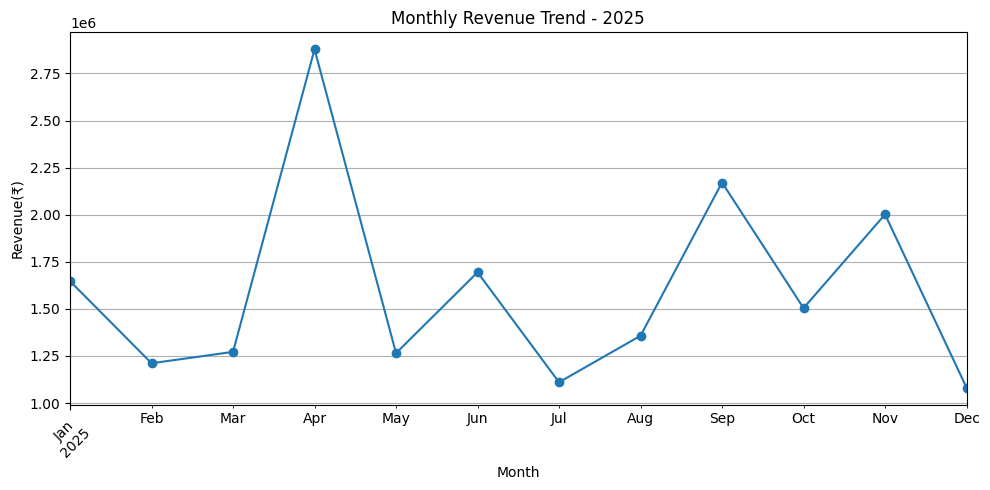

In [51]:
monthly_sales = df.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(10,5))
monthly_sales.plot(kind='line',marker='o')
plt.title('Monthly Revenue Trend - 2025')
plt.xlabel('Month')
plt.ylabel('Revenue(₹)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

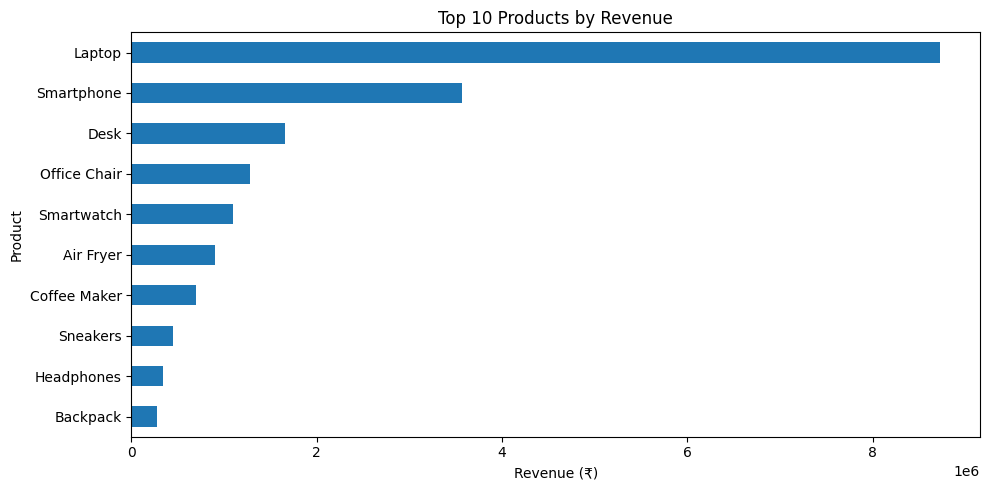

In [52]:
product_sales = (
    df.groupby('Product')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
product_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (₹)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

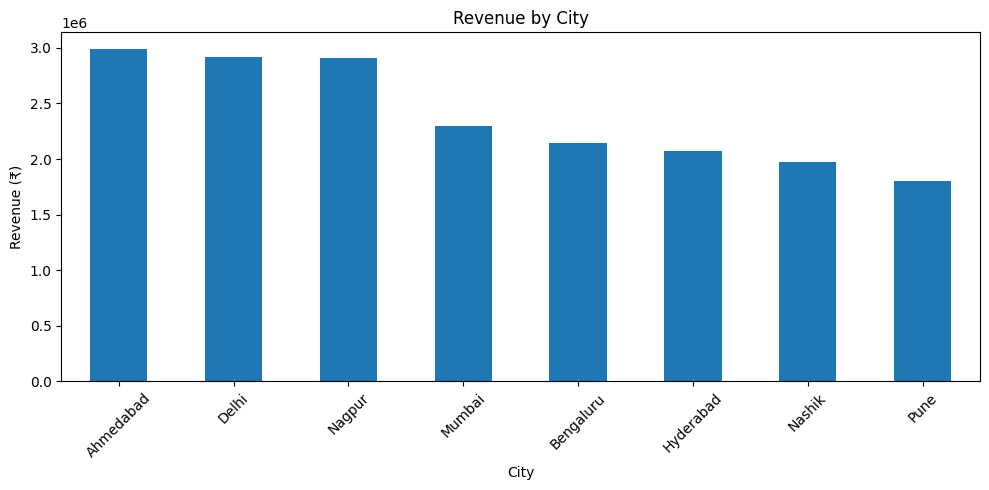

In [53]:
city_sales = (
    df.groupby('City')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
city_sales.plot(kind='bar')

plt.title('Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

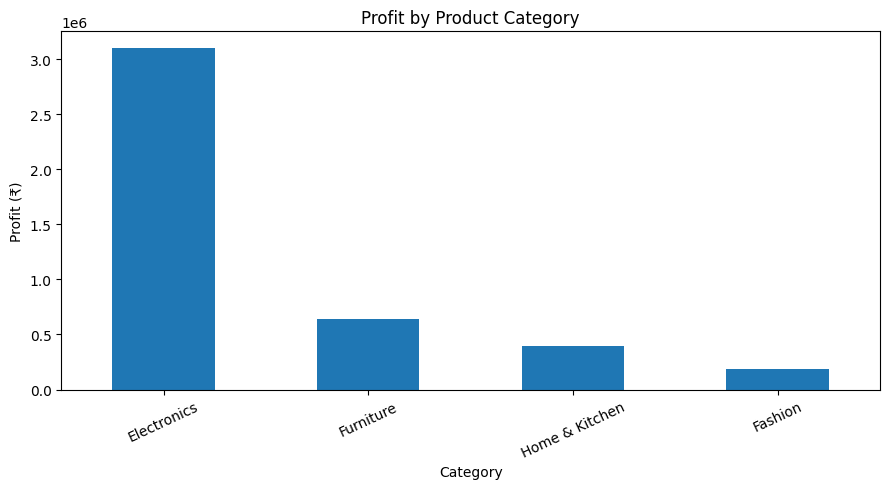

In [54]:
category_profit = (
    df.groupby('Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_profit.plot(kind='bar')

plt.title('Profit by Product Category')
plt.xlabel('Category')
plt.ylabel('Profit (₹)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [55]:
plt.savefig('monthly_revenue.png', dpi=300,bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [56]:
# 1. Best-selling product by revenue
product_sales = df.groupby('Product')['Revenue'].sum()
best_product = product_sales.idxmax()

# 2. Best-performing city
city_sales = df.groupby('City')['Revenue'].sum()
best_city = city_sales.idxmax()

# 3. Best sales month
df['Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Revenue'].sum()
best_month = monthly_sales.idxmax()

# 4. Most profitable category
category_profit = df.groupby('Category')['Profit'].sum()
best_category = category_profit.idxmax()

# 5. Profit margin
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
profit_margin = (total_profit / total_revenue) * 100

print("===== BUSINESS INSIGHTS =====")
print("Top product:", best_product)
print("Top city:", best_city)
print("Best sales month:", best_month)
print("Most profitable category:", best_category)
print(f"Overall profit margin: {profit_margin:.2f}%")

===== BUSINESS INSIGHTS =====
Top product: Laptop
Top city: Ahmedabad
Best sales month: 2025-04
Most profitable category: Electronics
Overall profit margin: 22.50%


In [57]:
import os

os.makedirs("Ecommerce_Sales_Analysis/visualizations", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [58]:
import matplotlib.pyplot as plt
import pandas as pd
import os

folder = "Ecommerce_Sales_Analysis/visualizations"
os.makedirs(folder, exist_ok=True)

df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month'] = df['Order_Date'].dt.to_period('M')

charts = [
    ("monthly_revenue.png",
     df.groupby('Month')['Revenue'].sum(),
     "Monthly Revenue Trend", "line"),
    ("top_products.png",
     df.groupby('Product')['Revenue'].sum().nlargest(10).sort_values(),
     "Top 10 Products by Revenue", "barh"),
    ("city_revenue.png",
     df.groupby('City')['Revenue'].sum().sort_values(ascending=False),
     "Revenue by City", "bar"),
    ("category_profit.png",
     df.groupby('Category')['Profit'].sum().sort_values(ascending=False),
     "Profit by Category", "bar")
]

for filename, data, title, chart_type in charts:
    plt.figure(figsize=(10, 5))
    data.plot(kind=chart_type)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{folder}/{filename}", dpi=300)
    plt.close()

print("All 4 charts saved successfully!")

All 4 charts saved successfully!


In [59]:
readme = """
# E-Commerce Sales & Customer Analysis

## Project Overview
This project analyzes e-commerce sales data to identify
revenue trends, top-performing products, city performance,
and product category profitability.

## Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab

## Dataset
600 practice sales records from 2025.

## Analysis
- Business KPIs
- Product revenue analysis
- Monthly revenue trends
- City-wise sales comparison
- Profit by product category

## Business Value
The analysis helps identify strong-performing products,
sales trends, geographic opportunities, and profitability
patterns.

## Note
This is a portfolio project using a practice dataset.
"""

with open("Ecommerce_Sales_Analysis/README.md", "w") as f:
    f.write(readme.strip())

print("README created successfully!")

README created successfully!


In [60]:
import shutil
shutil.make_archive(
    "Ecommerce_Sales_Analysis",
    "zip",
    root_dir="Ecommerce_Sales_Analysis"
)
print("Project ZIP created successfully!")

Project ZIP created successfully!
